In [1]:
# import libraries 
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# load data 
data = pd.read_csv("/kaggle/input/datasets/ritvik1909/indian-places-to-visit-reviews-data/Review_db.csv")

In [3]:
data.head()

,City,Place,Review,Rating,Name,Date,Raw_Review
0,Aamby Valley City,19 Degree North,aamby valley beautiful place clear blue skies ...,5,Anonymous,NaN,Aamby valley is a beautiful place with its cle...
1,Aamby Valley City,19 Degree North,executed obt akshay thanx team thoroughly enjo...,4,Anonymous,NaN,Very well executed obt by Akshay.... Thanx as ...
2,Aamby Valley City,19 Degree North,awesome experience atv tracts obstacles mainta...,5,Anonymous,NaN,Awesome experience at the ATV\nTracts and obst...
3,Aamby Valley City,19 Degree North,visited aamby valley yesterday short excursion...,4,Anonymous,NaN,we visited the Aamby Valley yesterday for shor...
4,Aamby Valley City,19 Degree North,far mumbai place finest adventure places visit...,5,Anonymous,NaN,"Not far from Mumbai, this place is one of the ..."


In [4]:
data.shape

(1482466, 7)

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1482466 entries, 0 to 1482465
Data columns (total 7 columns):
 #   Column      Non-Null Count    Dtype  
---  ------      --------------    -----  
 0   City        1482466 non-null  object 
 1   Place       1482466 non-null  object 
 2   Review      1482466 non-null  object 
 3   Rating      1482466 non-null  int64  
 4   Name        1482466 non-null  object 
 5   Date        0 non-null        float64
 6   Raw_Review  1482466 non-null  object 
dtypes: float64(1), int64(1), object(5)
memory usage: 79.2+ MB


In [6]:
data.isna().sum()

City                0
Place               0
Review              0
Rating              0
Name                0
Date          1482466
Raw_Review          0
dtype: int64

In [7]:
# drop data
data = data.drop(columns = ['Date'])

In [8]:
data.head()

,City,Place,Review,Rating,Name,Raw_Review
0,Aamby Valley City,19 Degree North,aamby valley beautiful place clear blue skies ...,5,Anonymous,Aamby valley is a beautiful place with its cle...
1,Aamby Valley City,19 Degree North,executed obt akshay thanx team thoroughly enjo...,4,Anonymous,Very well executed obt by Akshay.... Thanx as ...
2,Aamby Valley City,19 Degree North,awesome experience atv tracts obstacles mainta...,5,Anonymous,Awesome experience at the ATV\nTracts and obst...
3,Aamby Valley City,19 Degree North,visited aamby valley yesterday short excursion...,4,Anonymous,we visited the Aamby Valley yesterday for shor...
4,Aamby Valley City,19 Degree North,far mumbai place finest adventure places visit...,5,Anonymous,"Not far from Mumbai, this place is one of the ..."


In [9]:
data.duplicated().sum()

np.int64(14220)

In [10]:
data['Rating'].describe()

count    1.482466e+06
mean     4.231932e+00
std      8.726440e-01
min      1.000000e+00
25%      4.000000e+00
50%      4.000000e+00
75%      5.000000e+00
max      5.000000e+00
Name: Rating, dtype: float64

In [11]:
data['Rating'].value_counts().sort_index()

Rating
1      8821
2     57664
3    206493
4    517372
5    692116
Name: count, dtype: int64

In [12]:
# dropping duplicates
data = data.drop_duplicates()
data.shape

(1468246, 6)

## **Text Preprocessing**

In [13]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

In [14]:
# Download required NLTK data 
nltk.download('stopwords',quiet = True)
nltk.download('wordnet',quiet = True)
nltk.download('omw-1.4',quiet = True)

True

In [15]:
# intialize tools
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

In [16]:
def clean_text(text):
    # convert to lowercase
    text = str(text).lower()
    # Remove html tags 
    text = re.sub(r'<.*?>',' ',text)
    #Remove URLs
    text = re.sub(r"http\S+|www\S+"," ",text)
    # Remove special charcters and numbers (keep only letters)
    text = re.sub(r'[^a-zA-Z\s]'," ",text)
    # Remove extra whitespaces
    text = re.sub(r"\s+"," ",text).strip()
    # Remove stopwords and lemmatize
    words = text.split()
    words = [lemmatizer.lemmatize(word) for word in words if word not in stop_words]
    return ' '.join(words)

In [17]:
# apply cleaning to Review column
data['Clean_Review'] =  data['Review'].apply(clean_text)

In [18]:
data['Review'].iloc[0]

'aamby valley beautiful place clear blue skies fresh green grass family visited aamby valley celebrate mother birthday mom splendid time thanks pinky bharadwaj handling booking bombay'

In [19]:
data['Clean_Review'].iloc[0]

'aamby valley beautiful place clear blue sky fresh green grass family visited aamby valley celebrate mother birthday mom splendid time thanks pinky bharadwaj handling booking bombay'

## **Creating Sentiment Labels(Target Variable)**

In [20]:
# Feature Enginnering 
def get_sentiment(rating):
    if rating <= 2:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    else:
        return 'Positive'

In [21]:
# Applying Function
data['Sentiment'] = data['Rating'].apply(get_sentiment)

In [22]:
# Checking Distribution 
data['Sentiment'].value_counts()/len(data)*100

Sentiment
Positive    81.442074
Neutral     14.033820
Negative     4.524106
Name: count, dtype: float64

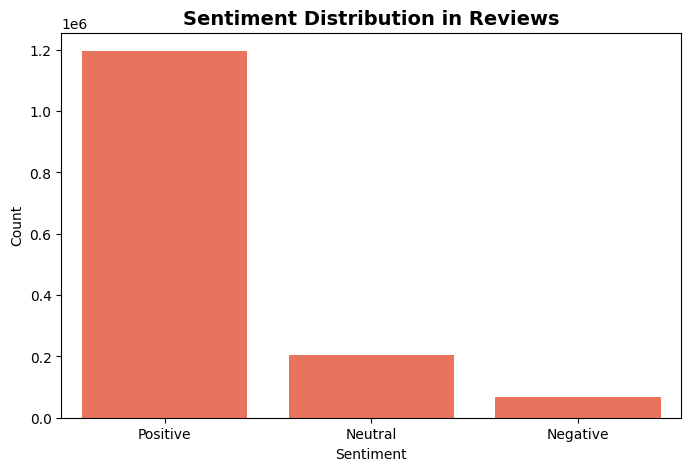

In [23]:
## Visualizing the distribution
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize = (8,5) )
sns.countplot(x = 'Sentiment',data = data,color = 'tomato')
plt.title('Sentiment Distribution in Reviews',fontsize = 14, fontweight = 'bold')
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.show()

## **Handle Class Imbalance(Downsampling)**
- why downsampling.
  1. Fairness.
  2. Speed.
  3. Better Accuracy.


In [24]:
# 1. Find the size of our smallest class (negative)
min_count = 66425

# 2. sample that many rows from each class
pos_sample = data[data['Sentiment']== 'Positive'].sample(n= min_count,random_state = 42)
neu_sample = data[data['Sentiment']== 'Neutral'].sample(n= min_count,random_state = 42)
neg_sample = data[data['Sentiment'] == 'Negative'] # Take all negatives

# 3. combine them into a new balanced dataFrame
data_balanced = pd.concat([pos_sample,neu_sample,neg_sample])

# 4. Shuffle the data so Postive/Negative aren't grouped togather 
data_balanced = data_balanced.sample(frac = 1,random_state = 42).reset_index(drop = True)

# checking results of  new distributions 
print("Data Shape: ",data_balanced.shape)
data_balanced['Sentiment'].value_counts()

Data Shape:  (199275, 8)


Sentiment
Negative    66425
Positive    66425
Neutral     66425
Name: count, dtype: int64

## **Train-Test Split**

In [25]:
data_balanced.head()

,City,Place,Review,Rating,Name,Raw_Review,Clean_Review,Sentiment
0,Gangtok,Banjhakri Water Falls,km gangtok city downhill district court road r...,2,Anonymous,It is about 3-4 km from the Gangtok city downh...,km gangtok city downhill district court road r...,Negative
1,Srinagar,Nigeen Lake,nagin lake quiet beautiful views nice shikara ...,5,Anonymous,Nagin lake is very quiet and beautiful..... t...,nagin lake quiet beautiful view nice shikara r...,Positive
2,Jaipur,Jal Mahal,visited oct photo stop spot jaipur siteseen vi...,3,Anonymous,Visited oct'17. Its a photo stop spot during j...,visited oct photo stop spot jaipur siteseen vi...,Neutral
3,New Delhi,India Gate,site memorial brilliantly chosen lutyens desig...,1,Anonymous,The site of this memorial was brilliantly chos...,site memorial brilliantly chosen lutyens desig...,Negative
4,New Delhi,Swaminarayan Akshardham,visitor new delhi new temple huge piece land s...,3,Anonymous,This is a must for all visitor to New Delhi. T...,visitor new delhi new temple huge piece land s...,Neutral


In [26]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
# Seprate Features (X)  and Target(Y)
X = data_balanced['Clean_Review']
y = data_balanced['Sentiment']

# Split
# stratify = y ensures the ratio of sentiments remains equal in both sets
X_train , X_test , y_train , y_test = train_test_split(X,y,test_size = 0.2,random_state=42,stratify=y)
 

# Intialize TF-IDF Vectorizer 
# max_feature = 5000 , keeps the top 5000 most important words to save memeory
tfidf = TfidfVectorizer(max_features=5000)

# Convert text --> Numbers 
# Fit on Training data , transform both
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [27]:
print(X_train_tfidf.shape,X_test_tfidf.shape)

(159420, 5000) (39855, 5000)


In [28]:
print(len(tfidf.vocabulary_)) # vocab size

5000


## **Train Naive Bayes Model (BaseLine)**

In [29]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import  accuracy_score, classification_report

# Intialize the Model 
model = MultinomialNB()

# Train the model
model.fit(X_train_tfidf,y_train)

MultinomialNB()

In [30]:
# Predict
y_pred = model.predict(X_test_tfidf)

In [31]:
# Calculate Accuracy
print(accuracy_score(y_test,y_pred))


0.7109020198218542


In [32]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

    Negative       0.70      0.72      0.71     13285
     Neutral       0.60      0.64      0.62     13285
    Positive       0.84      0.78      0.81     13285

    accuracy                           0.71     39855
   macro avg       0.72      0.71      0.71     39855
weighted avg       0.72      0.71      0.71     39855



In [33]:
def test_review(text: str,model_name):

    # clean text
    cleaned_custom = clean_text(text)

    # convert to tfidf numbers 
    custom_tfidf = tfidf.transform([cleaned_custom])

    # predit 
    prediction = model_name.predict(custom_tfidf)
    return  {"Review": my_custom_review, "AI Prediction": prediction[0]}

In [34]:
test_review("This place was very dirty,terrible experience and bad food quality",model)

NameError: name 'my_custom_review' is not defined

## **Logestic Regression**

In [ ]:
from sklearn.linear_model import  LogisticRegression
# intialize
lr_model = LogisticRegression(max_iter=1000,random_state=42)
# fit
lr_model.fit(X_train_tfidf,y_train)
#predict 
y_pred = lr_model.predict(X_test_tfidf)

In [ ]:
print(accuracy_score(y_test,y_pred))

In [ ]:
print(classification_report(y_test,y_pred))

In [ ]:
test_review("This place is beautiful but the service was slow.",lr_model)

## **Model 3: SVM**

In [ ]:
from sklearn.svm import LinearSVC
# intialize
svm_model = LinearSVC(max_iter=10000,random_state=42)
# fit
svm_model.fit(X_train_tfidf,y_train)
#predict 
y_pred = svm_model.predict(X_test_tfidf)


In [ ]:
print(accuracy_score(y_test,y_pred))

In [ ]:
print(classification_report(y_test,y_pred))

In [ ]:
test_review("This place is beautiful but the service was slow.",svm_model)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import joblib

models = ['Naive Bayes', 'Logistic Regression', 'Linear SVM']
accuracies = [71.09, 85.00, 85.73]

plt.figure(figsize=(10, 6))
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']
bars = plt.bar(models, accuracies, color=colors, edgecolor='black', linewidth=1.2)

# Add value labels on top of bars
for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, 
             f'{acc}%', ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.title(' Model Comparison: Accuracy Scores', fontsize=14, fontweight='bold')
plt.ylabel('Accuracy (%)', fontsize=12)
plt.ylim(0, 100)
plt.axhline(y=85.73, color='green', linestyle='--', alpha=0.5, label='Best Score')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Negative', 'Neutral', 'Positive'],
            yticklabels=['Negative', 'Neutral', 'Positive'])
plt.title('Confusion Matrix - Linear SVM (Best Model)', fontsize=14, fontweight='bold')
plt.ylabel('Actual Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
# final testing 
r1 = 'The place was dirty and terrible.'
r2 = 'Average experience nothing special.'
r3 = 'Loved the view! Amazing food and great service.'

In [ ]:
test_review(r1,svm_model)
test_review(r2,svm_model)
test_review(r3,svm_model)

In [ ]:
# Save SVM model
joblib.dump(svm_model, 'best_sentiment_model.pkl')
# Save TF-IDF vectorizer (needed to convert future text)
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')

print("✅ Model and Vectorizer saved successfully!")
print("📁 Files created: best_sentiment_model.pkl, tfidf_vectorizer.pkl")